In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [3]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna()

X = df.drop("target", axis=1).values
y = df["target"].values

print("Dataset Shape:", df.shape)
print("Target Distribution:")
print(pd.Series(y).value_counts())

Dataset Shape: (302, 14)
Target Distribution:
1    164
0    138
Name: count, dtype: int64


In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

Training Samples: 211
Validation Samples: 45
Testing Samples: 46


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

trained_models = {}

for name, model in models.items():

    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully
SVM trained successfully
KNN trained successfully


C:\Users\mahir\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [8]:
def calculate_metrics(actual, predicted):

    TP = np.sum((actual == 1) & (predicted == 1))
    TN = np.sum((actual == 0) & (predicted == 0))
    FP = np.sum((actual == 0) & (predicted == 1))
    FN = np.sum((actual == 1) & (predicted == 0))

    accuracy = (TP + TN) / len(actual)

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

In [9]:
validation_results = []

for name, model in trained_models.items():

    predictions = model.predict(X_val_scaled)

    metrics = calculate_metrics(y_val, predictions)

    validation_results.append({
        "Model": name,
        **metrics
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8222,0.7667,0.9583,0.8519
1,Decision Tree,0.8000,0.7778,0.8750,0.8235
2,Random Forest,0.8222,0.7857,0.9167,0.8462
3,SVM,0.8000,0.7586,0.9167,0.8302
4,KNN,0.8000,0.7586,0.9167,0.8302


In [10]:
# Custom importance weights
precision_weight = 0.25
recall_weight = 0.35
f1_weight = 0.40

validation_df["Weighted Score"] = (
    validation_df["Precision"] * precision_weight +
    validation_df["Recall"] * recall_weight +
    validation_df["F1 Score"] * f1_weight
)

validation_df = validation_df.sort_values(
    by="Weighted Score",
    ascending=False
)

display(validation_df.round(4))

best_model_name = validation_df.iloc[0]["Model"]

print("Selected Best Model:", best_model_name)

,Model,Accuracy,Precision,Recall,F1 Score,Weighted Score
0,Logistic Regression,0.8222,0.7667,0.9583,0.8519,0.8678
2,Random Forest,0.8222,0.7857,0.9167,0.8462,0.8557
3,SVM,0.8000,0.7586,0.9167,0.8302,0.8426
4,KNN,0.8000,0.7586,0.9167,0.8302,0.8426
1,Decision Tree,0.8000,0.7778,0.8750,0.8235,0.8301


Selected Best Model: Logistic Regression


In [11]:
best_model = trained_models[best_model_name]

test_predictions = best_model.predict(X_test_scaled)

test_metrics = calculate_metrics(y_test, test_predictions)

print("Selected Model:", best_model_name)
print("\nFinal Test Performance:")

for metric, value in test_metrics.items():
    print(metric, ":", round(value, 4))

Selected Model: Logistic Regression

Final Test Performance:
Accuracy : 0.7609
Precision : 0.85
Recall : 0.68
F1 Score : 0.7556


In [12]:
test_results = []

for name, model in trained_models.items():

    predictions = model.predict(X_test_scaled)

    metrics = calculate_metrics(y_test, predictions)

    test_results.append({
        "Model": name,
        **metrics
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7609,0.8500,0.68,0.7556
1,Decision Tree,0.6957,0.8235,0.56,0.6667
2,Random Forest,0.7174,0.8333,0.60,0.6977
3,SVM,0.7609,0.8500,0.68,0.7556
4,KNN,0.7826,0.8571,0.72,0.7826


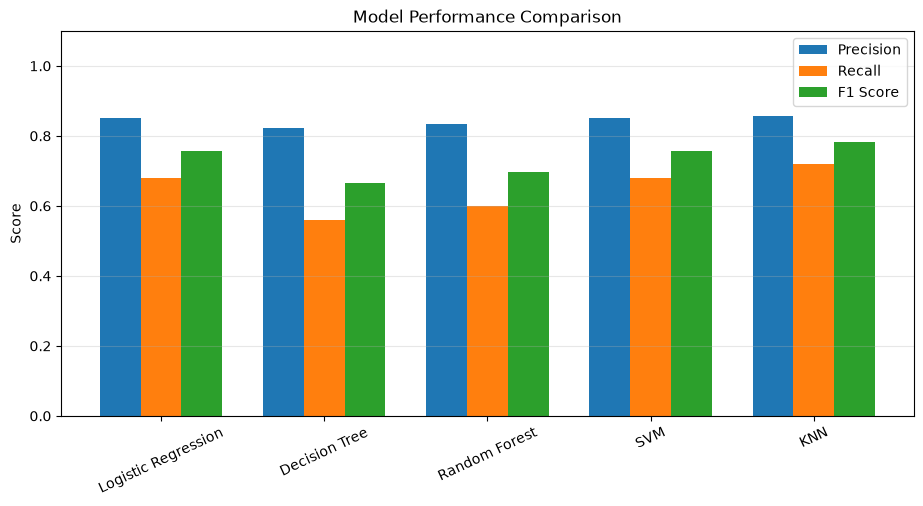

In [13]:
metrics_to_plot = ["Precision", "Recall", "F1 Score"]

x = np.arange(len(test_results_df))
width = 0.25

plt.figure(figsize=(11, 5))

for i, metric in enumerate(metrics_to_plot):

    plt.bar(
        x + (i - 1) * width,
        test_results_df[metric],
        width,
        label=metric
    )

plt.xticks(x, test_results_df["Model"], rotation=25)
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [14]:
class_counts = pd.Series(y_train).value_counts()

print("Training Class Distribution:")
print(class_counts)

class_0 = np.sum(y_train == 0)
class_1 = np.sum(y_train == 1)

minority_count = min(class_0, class_1)
majority_count = max(class_0, class_1)

imbalance_ratio = majority_count / minority_count

print("\nImbalance Ratio:", round(imbalance_ratio, 2))

if imbalance_ratio > 1.5:
    print("Dataset shows noticeable class imbalance.")
else:
    print("Dataset is relatively balanced.")

Training Class Distribution:
1    115
0     96
Name: count, dtype: int64

Imbalance Ratio: 1.2
Dataset is relatively balanced.


In [15]:
print("Best Model Selected:", best_model_name)

print("""
Conclusion:

Model selection should not depend only on accuracy.

Precision measures how many positive predictions are correct.
Recall measures how many actual positive cases are identified.
F1-score balances precision and recall.

Custom weighting allows greater importance to be assigned
to the metrics that matter most for the problem.

For medical prediction tasks, recall is particularly important
because missing a positive case can be costly.

The final model was selected using validation performance
and evaluated separately on the unseen test dataset.
""")

Best Model Selected: Logistic Regression

Conclusion:

Model selection should not depend only on accuracy.

Precision measures how many positive predictions are correct.
Recall measures how many actual positive cases are identified.
F1-score balances precision and recall.

Custom weighting allows greater importance to be assigned
to the metrics that matter most for the problem.

For medical prediction tasks, recall is particularly important
because missing a positive case can be costly.

The final model was selected using validation performance
and evaluated separately on the unseen test dataset.

